In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
import sympy as sp

from ortools.linear_solver import pywraplp
from IPython.display import display, Markdown

def md(title, body):
    """
    계산 결과를 Markdown 형식으로 출력하는 보조함수.

    title : 해석 블록의 제목
    body  : 분석 결과에 대한 자연어 설명
    """
    
    display(
        Markdown(
            f"### {title}\n\n{body}"
        )
    )

STATUS_LABEL = {
    pywraplp.Solver.OPTIMAL: "OPTIMAL",
    pywraplp.Solver.FEASIBLE: "FEASIBLE",
    pywraplp.Solver.INFEASIBLE: "INFEASIBLE",
    pywraplp.Solver.UNBOUNDED: "UNBOUNDED",
    pywraplp.Solver.NOT_SOLVED: "NOT_SOLVED",
}


md(
    "환경 설정 완료",
    "이제부터 모든 결과를 **수식 → Solver → DataFrame → 자연어 해석** 순서로 확인한다."
)


plt.rcParams["axes.unicode_minus"] = False

HUMAN_CAP = 80
TOKEN_CAP = 100
PROFIT_TARGET = 210

print("W03_Exercise_9_4_Goal_Programming_DeepDive.ipynb")

### 환경 설정 완료

이제부터 모든 결과를 **수식 → Solver → DataFrame → 자연어 해석** 순서로 확인한다.

W03_Exercise_9_4_Goal_Programming_DeepDive.ipynb


# Decision Making II — Week 3 Deep Dive
## Exercise 9-4 현대가구: Goal Programming 완전정복

---

## 이 Notebook의 질문

현대가구는 책상 1과 책상 2를 생산한다.

하지만 동시에 원하는 것이 여러 개다.

1. 정규작업시간 800시간을 초과하고 싶지 않다.
2. 책상 1의 수요 280개를 만족시키고 싶다.
3. 책상 2의 수요 400개를 만족시키고 싶다.
4. 총이익 1,500만원을 달성하고 싶다.

문제는 이 목표들을 모두 동시에 만족할 수 없다는 것이다.

따라서 이번 Notebook의 핵심 질문은 다음이다.

$$
\boxed{
\text{모든 목표를 완벽하게 만족할 수 없다면
어떤 목표를 얼마나 희생할 것인가?}
}
$$

---

# 학습 흐름

### Part A — 문제를 수학으로 번역
Problem
→ Decision Variables
→ Goal Expressions
→ Feasibility

### Part B — Goal Programming
Deviation Variables
→ Priority 1
→ Priority 2
→ Priority 3

### Part C — 두 표현 연결
대수
↔ Matrix
↔ Geometry
↔ Python

### Part D — Weighted Goal Programming
Priority를 제거하고
모든 희생을 벌금비용으로 환산

### Part E — Reconstruction
자료와 코드를 닫고
처음부터 모형을 다시 만든다.

---

## Source / Supplement 구분

### Source 직접 내용

- 연습문제 9-4의 생산시간, 이익, 수요, 목표
- Priority 1~3
- (2)의 벌금비용
- Goal Programming의 deviation / priority 구조

### 이해를 위한 보충

- Goal coefficient matrix $$G$$
- residual vector 해석
- 2차원 기하학
- penalty contour
- brute-force verification

보충 내용은 원문을 바꾸는 것이 아니라
같은 모형을 다른 representation으로 보는 것이다.

# 1. 문제를 아직 풀지 말고 구조부터 읽기

현대가구는 두 종류의 고급사무용 책상을 생산한다.

| 항목 | 책상 1 | 책상 2 |
|---|---:|---:|
| 작업시간 | 2시간 | 1시간 |
| 단위이익 | 2만원 | 3만원 |
| 최소 수요 | 280개 | 400개 |

정규 총 작업시간:

$$
800\text{시간}
$$

목표 총이익:

$$
1500\text{만원}
$$

---

## Priority 구조

### Priority 1

초과작업시간을 피한다.

$$
2x_1+x_2\le800
$$

---

### Priority 2

책상 1의 수요량을 만족한다.

$$
x_1\ge280
$$

책상 2의 수요량을 만족한다.

$$
x_2\ge400
$$

---

### Priority 3

총이익 1,500만원을 달성한다.

$$
2x_1+3x_2\ge1500
$$

---

## 여기서 중요한 distinction

이 네 조건은 모두 물리적으로 절대 지켜야 하는 Hard Constraint가 아니다.

이 문제에서는 모두 "목표"다.

즉 필요한 경우 위반할 수 있지만,

$$
\boxed{
\text{어떤 위반을 먼저 피할 것인가}
}
$$

가 Priority에 의해 결정된다.

# 2. Decision Variable

결정변수는 두 개다.

$$
x_1
=
\text{책상 1 생산량}
$$

$$
x_2
=
\text{책상 2 생산량}
$$

벡터로 묶으면

$$
\mathbf{x}
=
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
$$

이다.

---

## 구현 선택

생산수량이므로 이 Notebook에서는

$$
x_1,x_2\in\mathbb Z_{\ge0}
$$

인 정수변수로 구현한다.

즉 Python에서는 `IntVar`를 사용한다.

이 정수조건 자체가 문제 원문의 핵심 학습대상은 아니고,
실제 책상 개수라는 의미를 보존하기 위한 구현 선택이다.

# 3. 네 개의 Goal을 하나의 Linear Transformation으로 보기

여기부터는 이해를 위한 선형대수 보충이다.

네 Goal의 실제 성과를 한 번에 계산해보자.

Goal coefficient matrix를

$$
G=
\begin{bmatrix}
2 & 1\\
1 & 0\\
0 & 1\\
2 & 3
\end{bmatrix}
$$

라고 하자.

Decision vector:

$$
\mathbf{x}
=
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
$$

그러면

$$
G\mathbf{x}
=
\begin{bmatrix}
2 & 1\\
1 & 0\\
0 & 1\\
2 & 3
\end{bmatrix}
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
$$

이고 계산하면

$$
=
\begin{bmatrix}
2x_1+x_2\\
x_1\\
x_2\\
2x_1+3x_2
\end{bmatrix}.
$$

각 component는 순서대로

1. 총 작업시간
2. 책상 1 생산량
3. 책상 2 생산량
4. 총이익

이다.

---

## Dimension

$$
G\in\mathbb R^{4\times2}
$$

$$
\mathbf{x}\in\mathbb R^{2\times1}
$$

따라서

$$
G\mathbf{x}
\in
\mathbb R^{4\times1}.
$$

즉

$$
\boxed{
\mathbb R^2
\xrightarrow{G}
\mathbb R^4
}
$$

라고 볼 수 있다.

두 개의 생산수량을 입력하면
네 개의 Goal 성과로 변환되는 것으로 볼 수 있다.


In [2]:
G = np.array(
    [
        [2.0, 1.0], # 총 작업시간
        [1.0, 0.0], # 책상 1 생산량 S
        [0.0, 1.0], # 책상 2 생산량
        [2.0, 3.0], # 총이익
    ]
)

target = np.array(
    [
        800.0, # 총 작업시간
        280.0, # 책상 1 생산량
        400.0, # 책상 2 생산량
        1500.0, # 총이익
    ]
) # 각 goal 의 target을 같은 순서로 저장한다.

print(G)
print(target)
print("G.shape = ", G.shape) # 이때 G는 4행 2열의 행렬이다. 따라서, (4,2)
print("target.shape = ", target.shape) # 이때 target은 4차원 벡터이나 Numpy Array이므로, 따라서 shape는 (4, )이다. 따라서,
display(
    pd.DataFrame(
        G,
        index = ["총 작업시간", "책상 1 생산량", "책상 2 생산량", "총이익"],
        columns = ["X1", "X2"],
    )
)# 행렬의 각 coefficient는 각 goal의 계수를 표현한다. 즉, 총 작업시간은 2X1 + 1X2, 책상 1 생산량은 1X1 + 0X2, 책상 2 생산량은 0X1 + 1X2, 총이익은 2X1 + 3X2 이다.




[[2. 1.]
 [1. 0.]
 [0. 1.]
 [2. 3.]]
[ 800.  280.  400. 1500.]
G.shape =  (4, 2)
target.shape =  (4,)


,X1,X2
총 작업시간,2.0,1.0
책상 1 생산량,1.0,0.0
책상 2 생산량,0.0,1.0
총이익,2.0,3.0


# 4. "모든 수요를 정확히 만족하면?" 먼저 계산

수요 목표를 그대로 만족시키면

$$
x_1=280
$$

$$
x_2=400
$$

이다.

그러면 작업시간은

$$
2(280)+400
=
960
$$

시간이다.

하지만 정규 작업시간 목표는

$$
800
$$

시간이다.

따라서 최소수요를 모두 만족하는 순간 이미

$$
960-800
=
160
$$

시간의 초과작업이 발생한다.

즉

$$
\boxed{
\text{작업시간 목표와 두 수요목표는 동시에 완전히 만족될 수 없다.}
}
$$

이것이 Goal Programming이 필요한 이유다.

In [3]:
# 수요 목표를 정확히 만족하는 생산계획을 goal space에서 표현한다

x_demand_target = np.array(
    [
        280.0,
        400.0
    ]
) #책상 1을 280개, # 책상 2를 400개 생산하는 계획

performance = (
    G 
    @ x_demand_target
) # 이때 @ 연산자는 행렬곱을 의미한다. 즉, matrix multiplication을 의미한다. 
# G의 shape = 4,2 x의 shape는 2,1 이므로, 행렬곱의 결과는 4,1이다. 즉, 4개의 goal에 대한 성과를 한번에 계산한다.

print(performance)

performance_table = pd.DataFrame(
    {  
        'Goal': ['총 작업시간', '책상 1 생산량', '책상 2 생산량', '총이익'],
        'Actual': performance,
        'Target': target,
    }
) # 이때 각 행은 하나의 goal을 의미한다. 즉, 4개의 goal에 대한 성과를 한번에 계산한다.

display(performance_table)

print( "Total work time = ", performance[0], "hours" )
print("Overtime =", performance[0] - target[0], "hours")
print("Profit =", performance[3], "만원")


[ 960.  280.  400. 1760.]


,Goal,Actual,Target
0,총 작업시간,960.0,800.0
1,책상 1 생산량,280.0,280.0
2,책상 2 생산량,400.0,400.0
3,총이익,1760.0,1500.0


Total work time =  960.0 hours
Overtime = 160.0 hours
Profit = 1760.0 만원


# 5. 모든 Goal을 Hard Constraint처럼 강제해보자

Goal Programming에 들어가기 전에
PPT의 절차대로 가능해부터 확인한다.

모든 Goal을 반드시 만족시킨다고 가정하면:

$$
2x_1+x_2\le800
$$

$$
x_1\ge280
$$

$$
x_2\ge400
$$

$$
2x_1+3x_2\ge1500
$$

이다.

하지만

$$
x_1\ge280
$$

$$
x_2\ge400
$$

이므로 반드시

$$
2x_1+x_2
\ge
2(280)+400
=
960.
$$

그런데 동시에

$$
2x_1+x_2\le800
$$

이어야 한다.

즉

$$
960\le800
$$

을 요구하는 셈이다.

불가능하다.

따라서

$$
\boxed{\text{INFEASIBLE}}
$$

이다.

이건 Solver를 실행하기 전에도 수학적으로 확인할 수 있다.

In [4]:
# 정말 모든 Goal을 만족시키는 생산계획이 존재하는지 확인해보자 
# 진짜 INFEASIBLE한가?

feas_solver = pywraplp.Solver.CreateSolver(
    "SCIP"
) # SCIP 솔버 객체 생성\

if feas_solver is None:
    raise RuntimeError("Solver 생성 실패")
    # solver가 정상적으로 생성되지 않은 경우 즉시 중단한다.
x1_f = feas_solver.IntVar(
    0, feas_solver.infinity(),
    "책상 1 생산량",
)

x2_f = feas_solver.IntVar(
    0, feas_solver.infinity(),
    "책상 2 생산량",
)


feas_solver.Add(
    2*x1_f + x2_f <= 800
)

feas_solver.Add(
    x1_f >= 280
)

feas_solver.Add(
    x2_f >= 400
)

feas_solver.Add( 
    2*x1_f + 3*x2_f >= 1500
)

feas_solver.Minimize(
    0
) # 지금은 좋은 해를 찾는것이 아닌 , 가능해 존재 여부만 확인하므로 목적함수는 0이다.

feas_status = feas_solver.Solve()
#실제 FEASIBILITY problem을 푼다. 

if feas_status == pywraplp.Solver.OPTIMAL:
    print("Feasible")

elif feas_status == pywraplp.Solver.INFEASIBLE:
    print("INFEASIBLE")

else: 
    print("other solver status:", feas_status)

    #당연히 기대 결과는 infeasible

INFEASIBLE


# 6. 같은 Infeasibility를 2차원 공간에서 보기

의사결정변수가 두 개이므로
평면에 직접 그릴 수 있다.

가로축:

$$
x_1
$$

세로축:

$$
x_2
$$

---

## Work boundary

$$
2x_1+x_2=800
$$

즉

$$
x_2=800-2x_1.
$$

초과작업을 하지 않는 영역은 이 선 아래다.

---

## Desk 1 demand

$$
x_1=280
$$

목표 만족 영역은 오른쪽.

---

## Desk 2 demand

$$
x_2=400
$$

목표 만족 영역은 위쪽.

---

## Profit boundary

$$
2x_1+3x_2=1500
$$

즉

$$
x_2=
\frac{1500-2x_1}{3}.
$$

목표 만족 영역은 이 선 위쪽이다.

---

수요 두 개가 만나는 최소점

$$
(280,400)
$$

자체가 Work boundary 바깥에 있다.

따라서 네 목표의 완전한 공통영역은 없다.

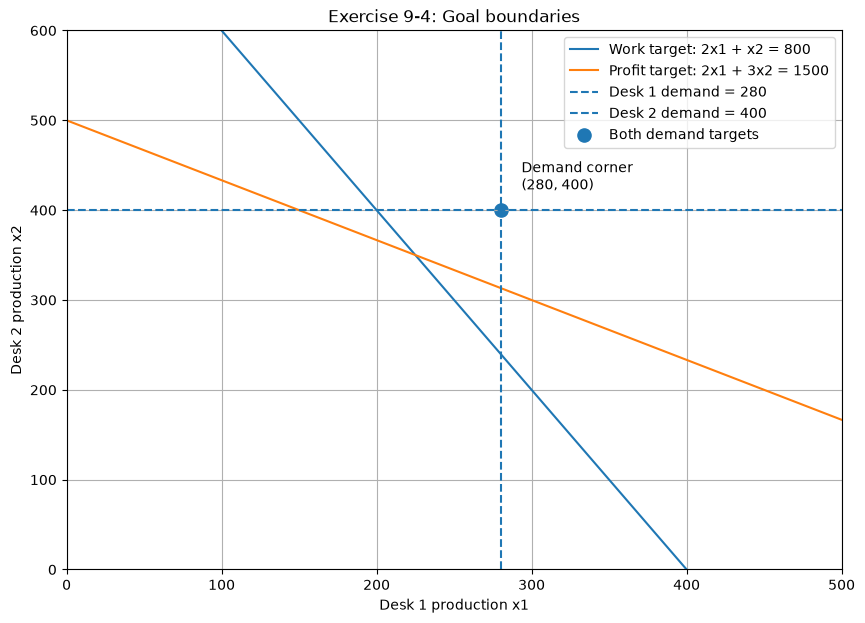

In [5]:
# Goal boundary를 2차원 평면에 그린다.


x1_grid = np.linspace(
    0,
    500,
    600,
)
# 책상 1 생산량을 0부터 500까지 촘촘하게 만든다.


work_boundary = (
    800
    - 2*x1_grid
)
# 2*x1 + x2 = 800을 x2에 대해 정리한 식이다.


profit_boundary = (
    1500
    - 2*x1_grid
) / 3
# 2*x1 + 3*x2 = 1500을 x2에 대해 정리한다.


plt.figure(
    figsize=(10, 7)
)
# 하나의 그림을 만든다.


plt.plot(
    x1_grid,
    work_boundary,
    label="Work target: 2x1 + x2 = 800",
)
# 정규 작업시간 800시간의 경계선이다.


plt.plot(
    x1_grid,
    profit_boundary,
    label="Profit target: 2x1 + 3x2 = 1500",
)
# 이익목표 1500만원의 경계선이다.


plt.axvline(
    280,
    linestyle="--",
    label="Desk 1 demand = 280",
)
# 책상 1 수요목표를 수직선으로 표시한다.


plt.axhline(
    400,
    linestyle="--",
    label="Desk 2 demand = 400",
)
# 책상 2 수요목표를 수평선으로 표시한다.


plt.scatter(
    [280],
    [400],
    s=90,
    label="Both demand targets",
)
# 두 수요목표를 동시에 최소한으로 만족하는 점을 찍는다.


plt.annotate(
    "Demand corner\n(280, 400)",
    (280, 400),
    xytext=(15, 15),
    textcoords="offset points",
)
# 해당 점이 무엇인지 글자로 표시한다.


plt.xlim(
    0,
    500,
)
# x축 표시범위를 정한다.


plt.ylim(
    0,
    600,
)
# y축 표시범위를 정한다.


plt.xlabel(
    "Desk 1 production x1"
)


plt.ylabel(
    "Desk 2 production x2"
)


plt.title(
    "Exercise 9-4: Goal boundaries"
)


plt.grid(True)


plt.legend()


plt.show()

# 7. Infeasible이므로 Deviation Variable을 도입한다

일반적인 Goal equation:

$$
f_i(x)+d_i^- -d_i^+=T_i
$$

---

## $$d_i^-$$

미달편차.

실제값이 목표보다 부족한 양.

---

## $$d_i^+$$

초과편차.

실제값이 목표보다 초과한 양.

---

# 현대가구의 네 Goal

## Goal 1 — 작업시간 800 이하

$$
2x_1+x_2+d_1^- -d_1^+=800
$$

나쁜 편차:

$$
d_1^+
$$

초과작업이 문제이기 때문이다.

---

## Goal 2 — 책상 1 최소 280개

$$
x_1+d_2^- -d_2^+=280
$$

나쁜 편차:

$$
\boxed{d_2^-}
$$

---

## Goal 3 — 책상 2 최소 400개

$$
x_2+d_3^- -d_3^+=400
$$

나쁜 편차:

$$
\boxed{d_3^-}
$$

---

## Goal 4 — 이익 최소 1500만원

$$
2x_1+3x_2+d_4^- -d_4^+=1500
$$

나쁜 편차:

$$
\boxed{d_4^-}
$$

# 8. Deviation은 residual을 양·음 두 방향으로 분해한 것이다

선형대수 보충.

우리가 앞에서 만든 성과벡터:

$$
Gx
$$

목표벡터:

$$
t.
$$

Goal equation 전체를 한 번에 쓰면:

$$
\boxed{
Gx+d^- -d^+=t
}
$$

이다.

여기서

$$
d^-=
\begin{bmatrix}
d_1^-\\
d_2^-\\
d_3^-\\
d_4^-
\end{bmatrix}
$$

$$
d^+=
\begin{bmatrix}
d_1^+\\
d_2^+\\
d_3^+\\
d_4^+
\end{bmatrix}.
$$

정리하면:

$$
t-Gx
=
d^- -d^+.
$$

즉 deviation variable은

$$
\boxed{
\text{Target과 Actual Performance 사이의 residual}
}
$$

을 양의 변수들로 분해한 것이다.

---

중요:

모든 deviation을 동시에 최소화하는 것이 아니다.

Goal의 방향과 Priority에 따라
"나쁜 deviation"만 목적함수에 들어간다.

In [6]:
# 어떤 생산계획을 넣어도 
# 실제 Goal 성과와 의미 있는 편차를 계산하는 함수를 만든다.

def evaluate_plan(x1, x2):
    #생산계획 (x1, x2)의 실제 성과와 의미있는 deviation을 계산한다.
    work = (
        2*x1
        +x2
    ) # 총 작업시간

    profit = (
        2*x1
        + 3*x2
    )

    overtime = max(
        0,
        work - 800,
    ) # goal1의 나쁜 편자 d1+ , 이는 800시간을 초과한 것에 대한 d1+

    undertime = max(
        0, 
        800 - work,
    # goal1 의 미달편차로서 d1-, part1에서는 벌점을 주지 않으나 part2에서의 weighted 모델에서 필요하다.
    )

    desk1_shortage = max(
        0,
        280 - x1,
    )
    desk2_shortage = max(
        0,
        400 - x2,
    )
    profit_shortage = max(
        0,
        1500 - profit,  
    ) # goal 4의 나쁜 편자 d4-

    return {
        "x1": x1,   
        "x2": x2,
        "work": work,
        "profit": profit,
        "d1+ overtime": overtime,
        "d1- undertime": undertime,
        "d2- desk1_shortage": desk1_shortage,
        "d3- desk2_shortage": desk2_shortage,
        "d4- profit_shortage": profit_shortage,
    } # 이렇게 하면 각 goal의 성과와 편차를 한번에 볼 수 있다. // 계산된 정보를 dict 형태로 반환한다.

sample_plans = pd.DataFrame(
    [ 
        evaluate_plan(0, 0),
        evaluate_plan(280, 400),
        evaluate_plan(200, 400),
        evaluate_plan(280, 240),
    ]
)

display(sample_plans)

    


,x1,x2,work,profit,d1+ overtime,d1- undertime,d2- desk1_shortage,d3- desk2_shortage,d4- profit_shortage
0,0,0,0,0,0,800,280,400,1500
1,280,400,960,1760,160,0,0,0,0
2,200,400,800,1600,0,0,80,0,0
3,280,240,800,1280,0,0,0,160,220


# 9. Part (1) — Preemptive Goal Programming

Priority는:

$$
P_1\gg P_2\gg P_3
$$

이다.

---

## Priority 1

초과작업을 피한다.

$$
\boxed{
\min d_1^+
}
$$

---

## Priority 2

책상 1과 책상 2의 수요 미달을 최소화한다.

$$
\boxed{
\min d_2^-+d_3^-
}
$$

단,

Priority 1에서 얻은 최적성과를 반드시 유지한다.

---

## Priority 3

이익 부족을 최소화한다.

$$
\boxed{
\min d_4^-
}
$$

단,

Priority 1과 Priority 2의 최적성과를 모두 유지한다.

---

## 핵심

다음 단계로 갈 때

$$
x_1,\;x_2
$$

자체를 고정하는 것이 아니다.

고정하는 것은

$$
\boxed{
\text{앞 Priority에서 달성한 최적 performance}
}
$$

이다.

In [7]:
# 공통 GoalPrograming 모델 생성. 
# Priority 단계마다 같은 goal equation을 반복해야하므로, 공통모형을 생성하는 함수를 만든다. 

def build_goal_model():
    solver = pywraplp.Solver.CreateSolver('SCIP')

    if solver is None:
        raise RuntimeError(
            "SCIP solver를 생성하지 못하였습니다"
        )

    x1 = solver.IntVar(0, solver.infinity(), 'desk1')
    x2 = solver.IntVar(0, solver.infinity(), 'desk2')
    d_plus = {} # goal 별 초과편차 d_i+를 저장할 dictionary
    d_minus = {} # goal 별 미달편차 d_i-를 저장할 dictionary

    for i in range(1, 5):
        d_plus[i] = solver.NumVar(
            0, solver.infinity(), f'd{i}_plus'
        )
        d_minus[i] = solver.NumVar(
            0, solver.infinity(), f'd{i}_minus'
        ) #각 goal의 초과편차와 미달편차는 0 이상의 연속변수로 둔다.

    solver.Add(
        2*x1
        + x2
        + d_minus[1]
        - d_plus[1]
        == 800 # goal1의 식, 총 작업시간의 목표는 800시간이다.
    ) # 다른 goal과 같은 형태 f(x) + d- - d+ = T 로 맞춘다. 그래야 d1+ 가 '초과작업' 을 뜻한다.

    solver.Add(
        x1
        + d_minus[2]
        - d_plus[2]
        == 280 # goal2의 식, 책상 1의 수요량은 280개이다.
    )

    solver.Add(
        x2
        + d_minus[3]
        - d_plus[3]
        == 400 # goal3의 식, 책상 2의 수요량은 400개이다.
    )
    
    solver.Add(
        2*x1
        + 3*x2
        + d_minus[4]
        - d_plus[4]
        == 1500 # goal4의 식, 총이익의 목표는 1500만원이다.
    )
    
    return solver, x1, x2, d_plus, d_minus
    # 모형과 변수들을 함께 돌려줘야 Priority 단계마다 목적함수와 추가 제약을 붙일 수 있다.


# 10. Priority 1 — 초과작업 최소화

$$
\min d_1^+
$$

제약은 네 개의 goal equation 뿐이다.

아직 앞 단계가 없으므로 추가로 고정할 성과도 없다.

In [8]:
# Priority 1 : 초과작업 d1+ 를 최소화한다.

s1, x1_p1, x2_p1, dp_p1, dm_p1 = build_goal_model()
# 공통 goal 모형을 새로 하나 만든다.

s1.Minimize(
    dp_p1[1]
) # goal1의 나쁜 편차 d1+ 만 목적함수에 넣는다.

status_p1 = s1.Solve()

p1_best = s1.Objective().Value()
# Priority 1에서 달성한 최적 성과. 다음 단계에서 이 값을 유지해야 한다.

print("status =", STATUS_LABEL.get(status_p1, status_p1))
print("P1 최적값 d1+ =", p1_best)
print("이때의 한 해 : x1 =", x1_p1.solution_value(), ", x2 =", x2_p1.solution_value())
# 이 단계의 x는 '여러 최적해 중 하나' 일 뿐이다. 다음 단계에서 고정하지 않는다.

status = OPTIMAL
P1 최적값 d1+ = 0.0
이때의 한 해 : x1 = -0.0 , x2 = 800.0


## Priority 1 해석

$$
d_1^{+*}=0
$$

즉 초과작업 없이도 모든 goal equation을 맞출 수 있다.

예를 들어 아무것도 안 만들면 $$(0,0)$$ 도 초과작업은 0이다.

따라서 Priority 1이 남기는 조건은

$$
d_1^+\le0
\;\Longleftrightarrow\;
2x_1+x_2\le800
$$

이다.

Solver가 보여준 $$x$$ 값은 최적해 중 하나일 뿐이다.
다음 단계로 넘기는 것은 이 $$x$$ 가 아니라 $$d_1^+\le0$$ 이라는 **성과**다.

# 11. Priority 2 — 수요 미달 최소화

$$
\min d_2^-+d_3^-
$$

단,

$$
d_1^+\le d_1^{+*}=0.
$$

---

## Solver 전에 손으로 먼저 예측

$$
d_2^-+d_3^-=(280-x_1)+(400-x_2)
$$

를 줄이려면 $$x_1+x_2$$ 를 키워야 한다.

그런데 작업시간은

$$
2x_1+x_2\le800.
$$

책상 1을 1개 줄이면 2시간이 남고,
그 2시간으로 책상 2를 2개 만들 수 있다.

즉 **같은 시간이면 책상 2를 채우는 쪽이 부족분을 더 많이 줄인다.**

따라서 책상 2를 먼저 400개 채우고, 남는 시간으로 책상 1을 만든다.

$$
x_2=400,\quad x_1=\frac{800-400}{2}=200
$$

$$
d_2^-=80,\quad d_3^-=0
$$

반대로 책상 1을 먼저 채우면

$$
(280,240)\Rightarrow d_2^-+d_3^-=160
$$

으로 두 배 나쁘다.

In [9]:
# Priority 2 : Priority 1의 성과를 유지한 채 수요 미달 d2- + d3- 를 최소화한다.

s2, x1_p2, x2_p2, dp_p2, dm_p2 = build_goal_model()
# 모형을 새로 만든다. 앞 단계의 solver를 재사용하지 않는다.

s2.Add(
    dp_p2[1]
    <= p1_best + 1e-6
) # Priority 1에서 달성한 성과를 유지한다. (1e-6 은 부동소수점 오차 여유)
# x1, x2 를 고정하는 것이 아니라 d1+ 의 '성과' 를 고정한다.

s2.Minimize(
    dm_p2[2]
    + dm_p2[3]
) # goal2, goal3의 나쁜 편차 d2-, d3- 를 같은 가중치로 더한다.

status_p2 = s2.Solve()

p2_best = s2.Objective().Value()
# Priority 2에서 달성한 최적 성과.

print("status =", STATUS_LABEL.get(status_p2, status_p2))
print("P2 최적값 d2- + d3- =", p2_best)
print("이때의 해 : x1 =", x1_p2.solution_value(), ", x2 =", x2_p2.solution_value())

status = OPTIMAL
P2 최적값 d2- + d3- = 80.0
이때의 해 : x1 = 200.0 , x2 = 400.0


# 12. Priority 3 — 이익 부족 최소화

$$
\min d_4^-
$$

단,

$$
d_1^+\le0,\qquad d_2^-+d_3^-\le80.
$$

---

## 예측

Priority 2에서 $$d_2^-+d_3^-=80$$ 을 만드는 해는

$$
(200,400)
$$

하나뿐이다. ($$x_1+x_2$$ 를 600으로 만들면서 $$2x_1+x_2\le800$$, $$x_2\le400$$ 을 지키는 점은 이것뿐.)

따라서 Priority 3이 움직일 여지는 없다.

$$
2(200)+3(400)=1600\ge1500
\Rightarrow d_4^-=0
$$

In [10]:
# Priority 3 : Priority 1, 2의 성과를 모두 유지한 채 이익 부족 d4- 를 최소화한다.

s3, x1_p3, x2_p3, dp_p3, dm_p3 = build_goal_model()

s3.Add(
    dp_p3[1]
    <= p1_best + 1e-6
) # Priority 1 성과 유지

s3.Add(
    dm_p3[2]
    + dm_p3[3]
    <= p2_best + 1e-6
) # Priority 2 성과 유지

s3.Minimize(
    dm_p3[4]
) # goal4의 나쁜 편차 d4- 만 최소화한다.

status_p3 = s3.Solve()

p3_best = s3.Objective().Value()

x1_star = round(x1_p3.solution_value())
x2_star = round(x2_p3.solution_value())
# 최종 생산계획. IntVar 이므로 정수로 반올림해 보관한다.

print("status =", STATUS_LABEL.get(status_p3, status_p3))
print("P3 최적값 d4- =", p3_best)
print("최종 해 : x1 =", x1_star, ", x2 =", x2_star)

status = OPTIMAL
P3 최적값 d4- = 0.0
최종 해 : x1 = 200 , x2 = 400


In [11]:
# 단계별 성과를 한 표로 모은다.

priority_table = pd.DataFrame(
    [
        {"Priority": "P1", "목적": "min d1+",       "최적값": p1_best, "고정한 앞 단계 성과": "-"},
        {"Priority": "P2", "목적": "min d2- + d3-", "최적값": p2_best, "고정한 앞 단계 성과": "d1+ <= 0"},
        {"Priority": "P3", "목적": "min d4-",       "최적값": p3_best, "고정한 앞 단계 성과": "d1+ <= 0, d2- + d3- <= 80"},
    ]
)

display(priority_table)


# 최종 해를 solver의 d 값이 아니라 evaluate_plan 으로 다시 계산해 대조한다.
# 목적함수에 들어가지 않은 편차(d4+ 등)는 solver가 임의의 값을 낼 수 있기 때문이다.

final_plan = pd.DataFrame(
    [
        evaluate_plan(x1_star, x2_star),
    ]
)

display(final_plan)

assert (x1_star, x2_star) == (200, 400)
assert abs(p1_best) < 1e-6
assert abs(p2_best - 80) < 1e-6
assert abs(p3_best) < 1e-6
# 손 계산 예측과 solver 결과가 같은지 확인한다.

md(
    "Preemptive Goal Programming 결과",
    f"최종 생산계획은 **책상 1 = {x1_star}개, 책상 2 = {x2_star}개** 이다.\n\n"
    f"- P1 : 초과작업 **0시간** — 작업시간을 정확히 800시간으로 사용\n"
    f"- P2 : 책상 1 수요 **80개 미달**, 책상 2 수요는 충족 — 같은 시간이면 책상 2가 부족분을 2배 빨리 줄이기 때문\n"
    f"- P3 : 이익 **{2*x1_star + 3*x2_star}만원** — 목표 1500만원을 넘으므로 이익 부족 0\n\n"
    "희생된 목표는 **책상 1 수요 하나뿐**이다. 초과작업을 허용하지 않는다는 P1이 가장 위에 있기 때문에 생긴 희생이다."
)

,Priority,목적,최적값,고정한 앞 단계 성과
0,P1,min d1+,0.0,-
1,P2,min d2- + d3-,80.0,d1+ <= 0
2,P3,min d4-,0.0,"d1+ <= 0, d2- + d3- <= 80"


,x1,x2,work,profit,d1+ overtime,d1- undertime,d2- desk1_shortage,d3- desk2_shortage,d4- profit_shortage
0,200,400,800,1600,0,0,80,0,0


### Preemptive Goal Programming 결과

최종 생산계획은 **책상 1 = 200개, 책상 2 = 400개** 이다.

- P1 : 초과작업 **0시간** — 작업시간을 정확히 800시간으로 사용
- P2 : 책상 1 수요 **80개 미달**, 책상 2 수요는 충족 — 같은 시간이면 책상 2가 부족분을 2배 빨리 줄이기 때문
- P3 : 이익 **1600만원** — 목표 1500만원을 넘으므로 이익 부족 0

희생된 목표는 **책상 1 수요 하나뿐**이다. 초과작업을 허용하지 않는다는 P1이 가장 위에 있기 때문에 생긴 희생이다.

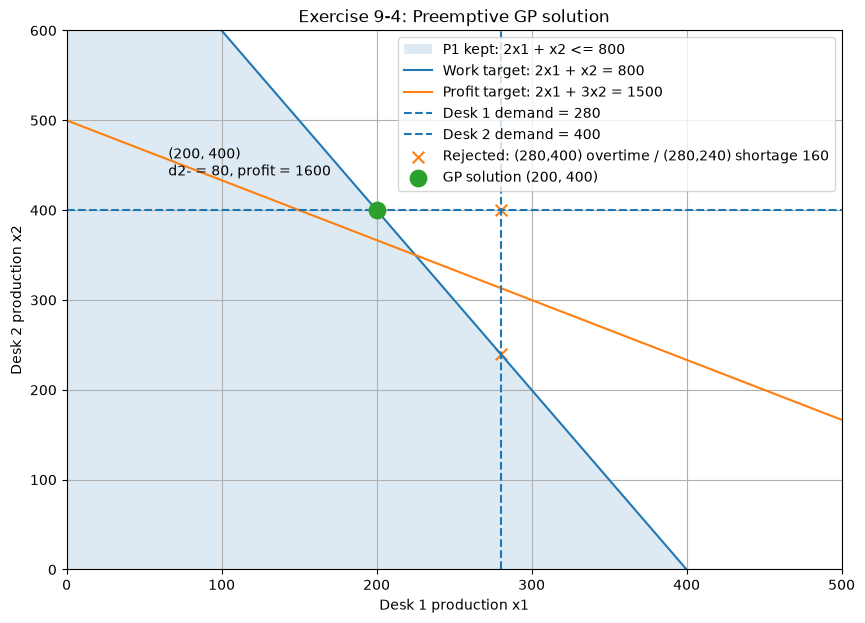

In [12]:
# Priority 단계가 해를 어디로 좁혀가는지 2차원 평면에서 본다.

plt.figure(
    figsize=(10, 7)
)

plt.fill_between(
    x1_grid,
    0,
    np.clip(work_boundary, 0, None),
    alpha=0.15,
    label="P1 kept: 2x1 + x2 <= 800",
)
# Priority 1이 남긴 영역 (초과작업 없음)

plt.plot(
    x1_grid,
    work_boundary,
    label="Work target: 2x1 + x2 = 800",
)

plt.plot(
    x1_grid,
    profit_boundary,
    label="Profit target: 2x1 + 3x2 = 1500",
)

plt.axvline(
    280,
    linestyle="--",
    label="Desk 1 demand = 280",
)

plt.axhline(
    400,
    linestyle="--",
    label="Desk 2 demand = 400",
)

plt.scatter(
    [280, 280],
    [400, 240],
    s=70,
    marker="x",
    label="Rejected: (280,400) overtime / (280,240) shortage 160",
)
# 비교용 후보 두 개

plt.scatter(
    [x1_star],
    [x2_star],
    s=140,
    zorder=5,
    label=f"GP solution ({x1_star}, {x2_star})",
)

plt.annotate(
    f"({x1_star}, {x2_star})\nd2- = 80, profit = {2*x1_star + 3*x2_star}",
    (x1_star, x2_star),
    xytext=(-150, 25),
    textcoords="offset points",
)

plt.xlim(0, 500)
plt.ylim(0, 600)

plt.xlabel("Desk 1 production x1")
plt.ylabel("Desk 2 production x2")
plt.title("Exercise 9-4: Preemptive GP solution")

plt.grid(True)
plt.legend(loc="upper right")
plt.show()

# 13. Part (2) — Weighted Goal Programming (다음 단계)

Priority 대신 모든 희생을 **벌금비용**으로 환산해 한 번에 최소화한다.

$$
\min\; w_1 d_1^+ + w_2 d_2^- + w_3 d_3^- + w_4 d_4^-
$$

$$w_i$$ 는 원문 (2)의 벌금비용을 그대로 넣는다.
`build_goal_model()` 을 그대로 재사용하고, 목적함수만 바꾸면 된다.

> TODO — 원문 (2)의 벌금비용 값을 확인한 뒤 작성